In [11]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

In [13]:
import pandas as pd
import os

file_path = os.path.expanduser("~/Downloads/2015.csv")

df = pd.read_csv(file_path)

print("Dataset Shape:", df.shape)

display(df.head())

Dataset Shape: (158, 12)


,Country,Region,Happiness Rank,Happiness Score,Standard Error,Economy (GDP per Capita),Family,Health (Life Expectancy),Freedom,Trust (Government Corruption),Generosity,Dystopia Residual
0,Switzerland,Western Europe,1,7.587,0.03411,1.39651,1.34951,0.94143,0.66557,0.41978,0.29678,2.51738
1,Iceland,Western Europe,2,7.561,0.04884,1.30232,1.40223,0.94784,0.62877,0.14145,0.43630,2.70201
2,Denmark,Western Europe,3,7.527,0.03328,1.32548,1.36058,0.87464,0.64938,0.48357,0.34139,2.49204
3,Norway,Western Europe,4,7.522,0.03880,1.45900,1.33095,0.88521,0.66973,0.36503,0.34699,2.46531
4,Canada,North America,5,7.427,0.03553,1.32629,1.32261,0.90563,0.63297,0.32957,0.45811,2.45176


In [14]:
df.shape

(158, 12)

In [15]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 158 entries, 0 to 157
Data columns (total 12 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Country                        158 non-null    object 
 1   Region                         158 non-null    object 
 2   Happiness Rank                 158 non-null    int64  
 3   Happiness Score                158 non-null    float64
 4   Standard Error                 158 non-null    float64
 5   Economy (GDP per Capita)       158 non-null    float64
 6   Family                         158 non-null    float64
 7   Health (Life Expectancy)       158 non-null    float64
 8   Freedom                        158 non-null    float64
 9   Trust (Government Corruption)  158 non-null    float64
 10  Generosity                     158 non-null    float64
 11  Dystopia Residual              158 non-null    float64
dtypes: float64(9), int64(1), object(2)
memory usage: 1

In [16]:
df.isnull().sum()

Country                          0
Region                           0
Happiness Rank                   0
Happiness Score                  0
Standard Error                   0
Economy (GDP per Capita)         0
Family                           0
Health (Life Expectancy)         0
Freedom                          0
Trust (Government Corruption)    0
Generosity                       0
Dystopia Residual                0
dtype: int64

In [20]:
df.describe()

,Happiness Rank,Happiness Score,Standard Error,Economy (GDP per Capita),Family,Health (Life Expectancy),Freedom,Trust (Government Corruption),Generosity,Dystopia Residual
count,158.000000,158.000000,158.000000,158.000000,158.000000,158.000000,158.000000,158.000000,158.000000,158.000000
mean,79.493671,5.375734,0.047885,0.846137,0.991046,0.630259,0.428615,0.143422,0.237296,2.098977
std,45.754363,1.145010,0.017146,0.403121,0.272369,0.247078,0.150693,0.120034,0.126685,0.553550
min,1.000000,2.839000,0.018480,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.328580
25%,40.250000,4.526000,0.037268,0.545808,0.856823,0.439185,0.328330,0.061675,0.150553,1.759410
50%,79.500000,5.232500,0.043940,0.910245,1.029510,0.696705,0.435515,0.107220,0.216130,2.095415
75%,118.750000,6.243750,0.052300,1.158448,1.214405,0.811013,0.549092,0.180255,0.309883,2.462415
max,158.000000,7.587000,0.136930,1.690420,1.402230,1.025250,0.669730,0.551910,0.795880,3.602140


In [21]:
print("Duplicate rows:", df.duplicated().sum())

print("Unique countries:", df['Country'].nunique())

print("Unique regions:", df['Region'].nunique())

Duplicate rows: 0
Unique countries: 158
Unique regions: 10


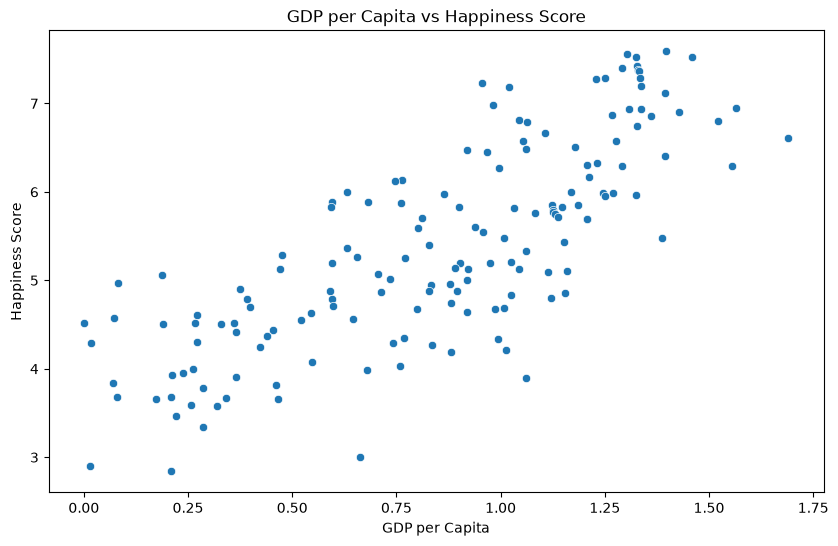

In [22]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='Economy (GDP per Capita)',
    y='Happiness Score'
)

plt.title('GDP per Capita vs Happiness Score')
plt.xlabel('GDP per Capita')
plt.ylabel('Happiness Score')

plt.show()

In [23]:
correlation = df['Economy (GDP per Capita)'].corr(
    df['Happiness Score']
)

print("GDP-Happiness Correlation:", correlation)

GDP-Happiness Correlation: 0.7809655268660213


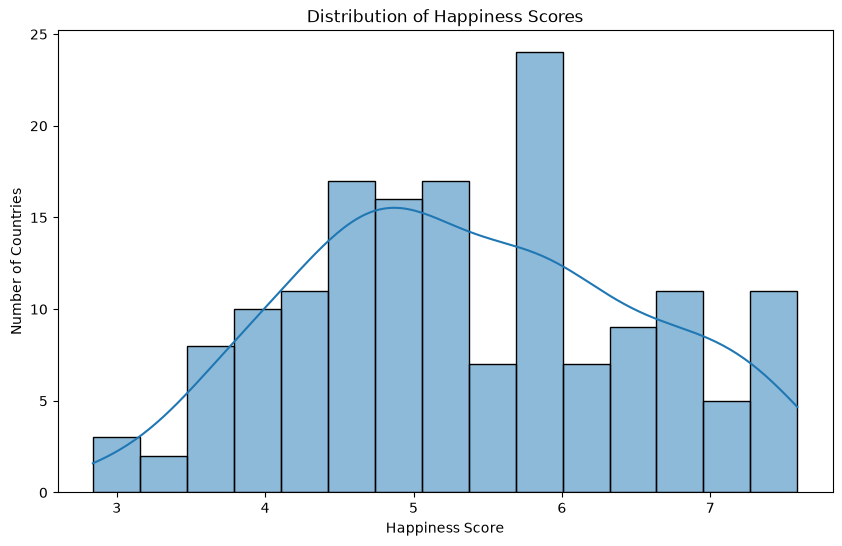

In [24]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x='Happiness Score',
    bins=15,
    kde=True
)

plt.title('Distribution of Happiness Scores')
plt.xlabel('Happiness Score')
plt.ylabel('Number of Countries')

plt.show()

In [25]:
X = df[
    [
        "Economy (GDP per Capita)",
        "Family",
        "Health (Life Expectancy)",
        "Freedom",
        "Trust (Government Corruption)",
        "Generosity"
    ]
]

y = df["Happiness Score"]

print("X Shape:", X.shape)
print("y Shape:", y.shape)

X Shape: (158, 6)
y Shape: (158,)


In [26]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (126, 6)
Testing data: (32, 6)


In [27]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(X_train, y_train)

print("Model training completed!")

Model training completed!


In [28]:
y_pred = model.predict(X_test)

print("Actual Values:", y_test.head().values)
print("Predicted Values:", y_pred[:5])

Actual Values: [4.307 5.987 4.194 2.905 5.057]
Predicted Values: [4.7601377  6.46907653 4.61372277 3.05290197 4.96414597]


In [29]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

MAE: 0.4023049853814398
MSE: 0.2419388283356373
RMSE: 0.49187277657503803
R2 Score: 0.8294705100069294


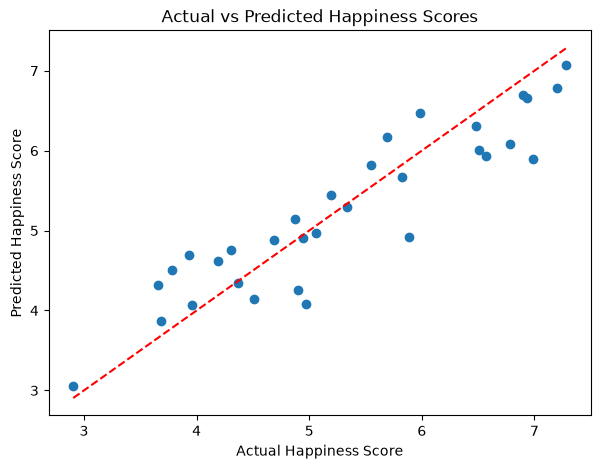

In [30]:
plt.figure(figsize=(7, 5))

plt.scatter(y_test, y_pred)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--'
)

plt.xlabel("Actual Happiness Score")
plt.ylabel("Predicted Happiness Score")
plt.title("Actual vs Predicted Happiness Scores")

plt.show()

In [31]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=200,
    random_state=42
)

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)

print("Random Forest training completed!")

Random Forest training completed!


In [32]:
rf_mae = mean_absolute_error(y_test, rf_pred)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_pred))
rf_r2 = r2_score(y_test, rf_pred)

print("Random Forest MAE:", rf_mae)
print("Random Forest RMSE:", rf_rmse)
print("Random Forest R2:", rf_r2)

Random Forest MAE: 0.4312018750000014
Random Forest RMSE: 0.5213109218055493
Random Forest R2: 0.8084476132641025


In [33]:
comparison = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest"],
    "MAE": [mae, rf_mae],
    "RMSE": [rmse, rf_rmse],
    "R2 Score": [r2, rf_r2]
})

display(comparison)

,Model,MAE,RMSE,R2 Score
0,Linear Regression,0.402305,0.491873,0.829471
1,Random Forest,0.431202,0.521311,0.808448


In [34]:
best_model = comparison.loc[comparison["R2 Score"].idxmax()]

print("Best Model:", best_model["Model"])
print("R2 Score:", best_model["R2 Score"])

Best Model: Linear Regression
R2 Score: 0.8294705100069294


In [35]:
coefficients = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": model.coef_
})

display(coefficients.sort_values(
    by="Coefficient",
    ascending=False
))

,Feature,Coefficient
1,Family,1.261558
3,Freedom,1.231449
2,Health (Life Expectancy),1.019769
0,Economy (GDP per Capita),0.876149
4,Trust (Government Corruption),0.811955
5,Generosity,0.635959


In [36]:
import pickle
import os

os.makedirs("models", exist_ok=True)

with open("models/happiness_model.pkl", "wb") as file:
    pickle.dump(model, file)

print("Model saved successfully!")

Model saved successfully!


In [37]:
with open("models/happiness_model.pkl", "rb") as file:
    loaded_model = pickle.load(file)

print("Model loaded successfully!")

Model loaded successfully!


In [38]:
new_country = pd.DataFrame([{
    "Economy (GDP per Capita)": 1.2,
    "Family": 1.0,
    "Health (Life Expectancy)": 0.8,
    "Freedom": 0.6,
    "Trust (Government Corruption)": 0.2,
    "Generosity": 0.3
}])

prediction = loaded_model.predict(new_country)

print("Predicted Happiness Score:", round(prediction[0], 2))

Predicted Happiness Score: 6.15


In [41]:
World Happiness Analysis and Prediction

Project Overview

This project analyzes the World Happiness Report 2015 dataset using Python, Pandas, Matplotlib and Seaborn.

It also uses Linear Regression to estimate Happiness Scores from socioeconomic factors.

Dataset

Source: "World Happiness Report – Kaggle" (https://www.kaggle.com/datasets/unsdsn/world-happiness)

Year used: 2015

Technologies Used

- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Scikit-learn
- Jupyter Notebook

Project Steps

1. Data Loading
2. Exploratory Data Analysis
3. Data Visualization
4. Feature Selection
5. Train-Test Split
6. Linear Regression
7. Model Evaluation
8. Model Saving
9. Happiness Score Prediction

Model Performance

- MAE: 0.4023
- RMSE: 0.4919
- R² Score: 0.8295

Conclusion

The project explores relationships between socioeconomic factors and reported happiness scores. A Linear Regression model was trained to estimate the reported scores using six selected factors.

This is an educational estimation exercise, not a causal analysis or future happiness forecast.

SyntaxError: invalid character '²' (U+00B2) (2965679869.py, line 41)